In [1]:
import sys 
sys.path.append('../src')

from data_processing.load import load_and_preprocess_data

from data_processing.utils import load_checkpoint, save_checkpoint, run_inference_bnn, run_svi
from models.model import quantile_bnn_model

import jax
import jax.numpy as jnp
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal
from numpyro.optim import Adam



In [2]:
jax.config.update('jax_num_cpu_devices', 6) # I have 8 physical cores

### Load data and preprocess
- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:
- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)

In [3]:
from operator import itemgetter
data = load_and_preprocess_data()
(X_train, X_test, Y_train_gen, Y_test_gen,
 Y_train_cf, Y_test_cf, Y_train_aval, Y_test_aval,
 sites_meta, feature_cols) = itemgetter(
    "X_train","X_test","Y_train_gen","Y_test_gen",
    "Y_train_cf","Y_test_cf","Y_train_aval","Y_test_aval",
    "sites_meta","feature_cols"
)(data)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Quantile BNN
input 
- X: (timestamps, wind parks, features)
- Quantiles: (q)

output: (q, timestamps)


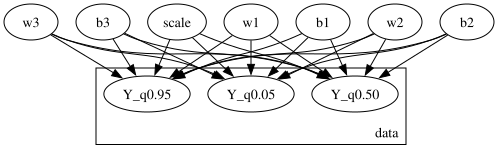

In [4]:
import numpyro
numpyro.render_model(
    quantile_bnn_model,
    model_args=(X_test,),
)

In [5]:
D_H = 8
args = {
    'num_warmup': 10,
    'num_samples': 30,
    'num_chains': 5,
}

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Run MCMC

In [46]:
samples = run_inference_bnn(quantile_bnn_model, args, rng_key, X_train, Y_train_gen, D_H)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]     -1.12      4.02     -0.11     -3.84      1.73     12.71      1.27
     b1[1]      1.40      2.70      0.54     -2.07      5.49      3.17      2.51
     b1[2]      0.23      2.83      0.24     -2.39      6.13      2.99      2.97
     b1[3]     -0.40      1.33     -1.10     -1.88      1.37      3.15      2.86
     b1[4]     -0.14      2.19     -0.11     -3.26      3.61      2.85      3.38
     b1[5]      0.18      2.57      0.89     -4.28      3.79      3.12      3.50
     b1[6]      0.31      5.93     -0.77     -6.89     11.27      3.08      2.56
     b1[7]     -0.43      1.77      0.25     -3.95      1.28      3.98      2.04
     b2[0]      1.67      2.69      1.47      0.69      4.90      6.56      1.44
     b2[1]     -2.96      2.86     -1.57     -6.21      1.32      3.94      1.81
     b2[2]     -1.60      2.65     -2.06     -4.94      1.64      2.88      3.27
     b2[3]      1.08      2

In [7]:
save_checkpoint(samples, "quantile_bnn_model", args, rng_key)

Saved checkpoint for model 'quantile_bnn_model': ../../checkpoints/quantile_bnn_model_2025-10-23_14-43-23_gen.pkl


'../../checkpoints/quantile_bnn_model_2025-10-23_14-43-23_gen.pkl'

In [ ]:
# taus = (0.05, 0.5, 0.95)
# nuts_kernel = NUTS(quantile_bnn_model)
# mcmc = MCMC(nuts_kernel, num_warmup=20, num_samples=50)
# mcmc.run(random.PRNGKey(0), X=X_train, Y=Y_train_cf, D_H=32, quantiles=taus)
# mcmc.print_summary()
# samples = mcmc.get_samples()

In [7]:
preds_MCMC = Predictive(quantile_bnn_model, samples)(rng_key_predict, X_test)

In [57]:
samples_cf = run_inference_bnn(quantile_bnn_model, args, rng_key, X_train, Y_train_cf, D_H)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      0.40      0.61      0.18     -0.25      1.48      2.55     33.59
     b1[1]      0.89      1.51      1.72     -1.82      2.47       nan     24.19
     b1[2]     -0.31      1.44      0.04     -2.04      1.86      2.54    290.02
     b1[3]     -0.97      1.25     -1.64     -1.93      1.47      2.54     81.54
     b1[4]      0.44      1.15      0.82     -1.61      1.78      2.54     67.76
     b1[5]      0.92      0.60      0.75      0.31      2.04      2.54     74.63
     b1[6]     -0.05      1.01     -0.60     -1.26      1.37      2.54     48.66
     b1[7]      0.37      1.32      0.90     -2.20      1.58       nan     68.56
     b2[0]     -0.03      1.44      0.31     -1.81      1.67      2.55     22.28
     b2[1]      0.25      1.15     -0.45     -0.85      1.65      2.56     18.09
     b2[2]      0.24      1.49      1.06     -1.99      1.80      2.54     59.42
     b2[3]      0.41      0

In [58]:
preds_MCMC_cf = Predictive(quantile_bnn_model, samples_cf)(rng_key_predict, X_test)

Run VI

In [65]:
guide = AutoNormal(quantile_bnn_model)
svi_result = run_svi(quantile_bnn_model, guide, rng_key, X_train, Y_train_cf, num_steps=1000)
params = svi_result.params
preds_VI = Predictive(quantile_bnn_model, guide=guide, params=params, num_samples=500)(rng_key_predict, X_test)


Final ELBO loss: 286708.250


### Evaluation

In [84]:
preds = preds_MCMC_cf
# CF: preds_VI and preds_MCMC_cf
# Gen: preds_MCMC

In [85]:
#preds = preds_MCMC # or preds_MCMC
q05 = preds["Y_q0.05"].mean(axis=0)
q50 = preds["Y_q0.50"].mean(axis=0)
q95 = preds["Y_q0.95"].mean(axis=0)


In [80]:
rmse = jnp.sqrt(jnp.mean((q50  - Y_test_gen) ** 2)) # * Y_test_aval
print("Test RMSE (Median):", rmse)

Test RMSE (Median): 97.504715


In [86]:
rmse = jnp.sqrt(jnp.mean((q50 * Y_test_aval - Y_test_gen) ** 2))
print("Test RMSE (Cf, Median):", rmse)

Test RMSE (Cf, Median): 942.3239


Empirical coverage of percentiles

In [87]:

inside = (Y_test_cf >= q05) & (Y_test_cf <= q95)
coverage_90 = inside.mean()
print(f"Empirical coverage (0.05–0.95): {coverage_90:.3f}")

below_median = (Y_test_gen <= q50).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")


Empirical coverage (0.05–0.95): 0.000
Below median (should be ~0.5): 0.019


### Plots

Variational Inference loss

Final ELBO loss: 286708.250


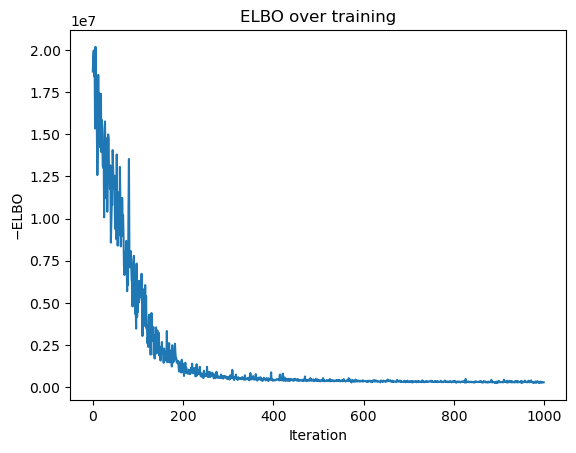

In [71]:
losses = svi_result.losses
print(f"Final ELBO loss: {losses[-1]:.3f}")
plt.plot(losses)
plt.title("ELBO over training")
plt.xlabel("Iteration")
plt.ylabel("−ELBO")
plt.show()


Different intervals (percentile vs. hdi vs. normal)

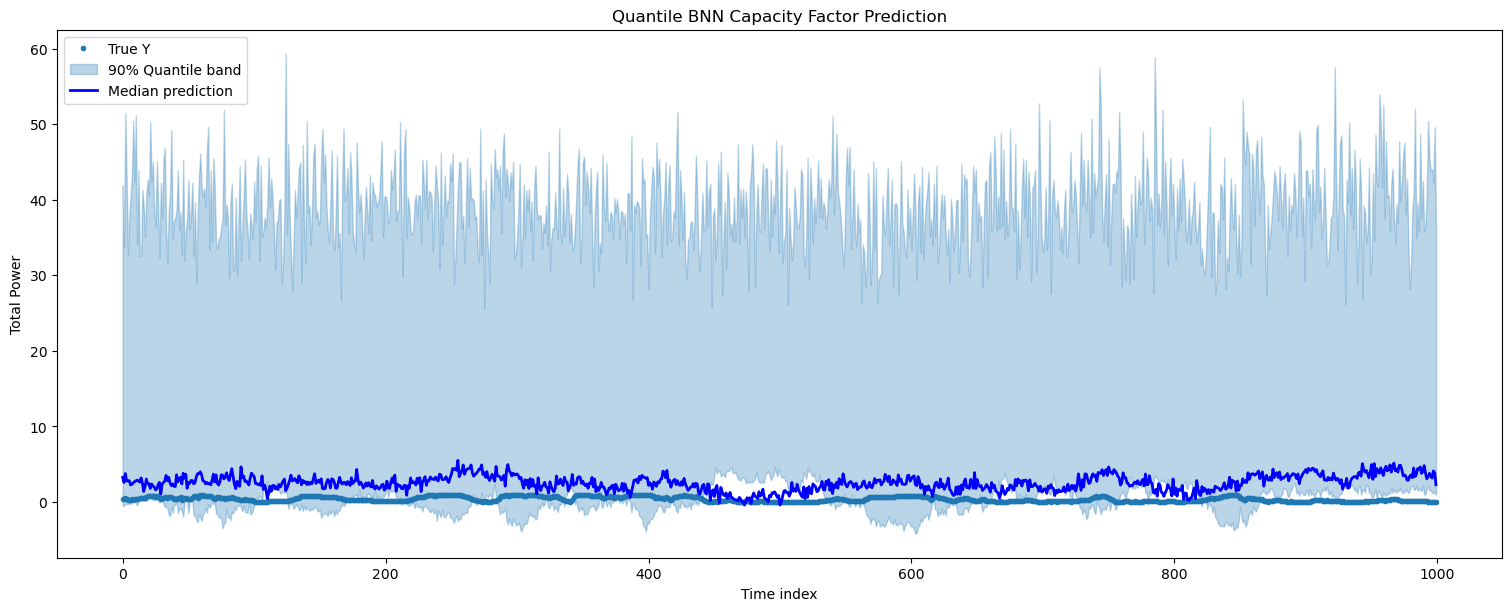

In [88]:
# Plot 90% CI
n_plot = 1000
X_new = np.arange(n_plot)
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(X_new, Y_test_cf[:n_plot], ".", label="True Y")
ax.fill_between(X_new, q05[:n_plot], q95[:n_plot], color="C0", alpha=.3, label="90% Quantile band")
ax.plot(X_new, q50[:n_plot], "b", lw=2, label="Median prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="Quantile BNN Capacity Factor Prediction")
ax.legend()
plt.show()


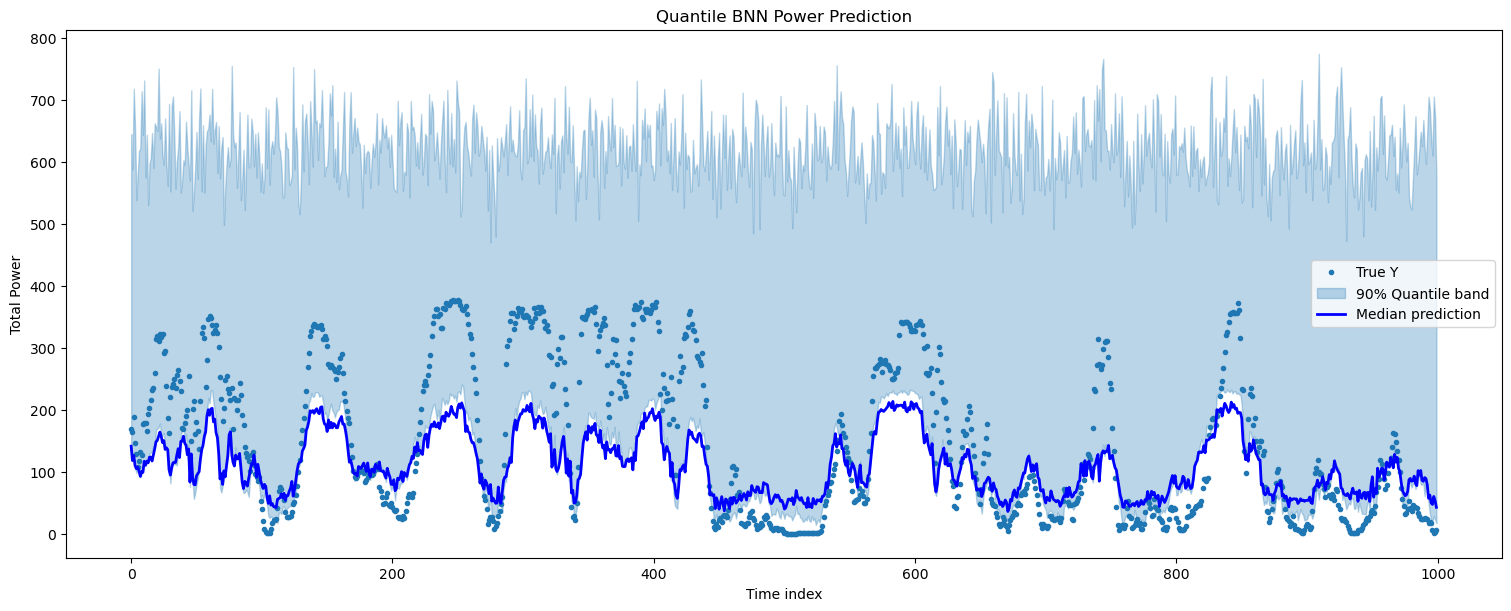

In [83]:
# Plot 90% CI
n_plot = 1000
X_new = np.arange(n_plot)
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(X_new, Y_test_gen[:n_plot], ".", label="True Y")
ax.fill_between(X_new, q05[:n_plot], q95[:n_plot], color="C0", alpha=.3, label="90% Quantile band")
ax.plot(X_new, q50[:n_plot], "b", lw=2, label="Median prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="Quantile BNN Power Prediction")
ax.legend()
plt.show()


PIT (Probability Integral Transform)
- Checks calibration of probabilistic forecasts
- Model well-calibrated -> values uniformly distributed
- For each observation $y_i$:
    - Take all model’s predictive samples for that data point
    - Compute how many of those samples are less than or equal to the actual observed value
    - PIT value $u_i = P_{\hat{Y_i}}​​(Y\leq y)$
    - with MCMC: $u_i \approx \frac{1}{S} \sum_{s=1}^S 1[y_i^{(s)}\leq y_i]$

In [89]:
preds=preds_MCMC

PIT mean (of median): 0.6520345519049823 (should be uniform if calibrated)


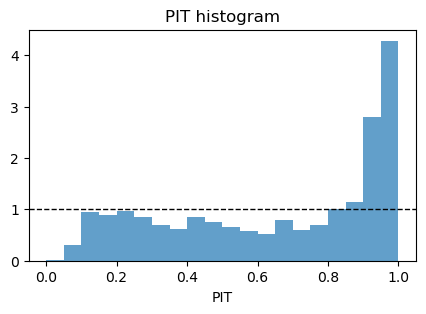

In [90]:
pits = np.array([percentileofscore(preds["Y_q0.50"][:, t], Y_test_gen[t], kind='mean') / 100.0 for t in range(preds["Y_q0.50"].shape[1])])
pits_mean = pits.mean()
print(f"PIT mean (of median): {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5,3))
plt.hist(pits, bins=20, range=(0,1), density=True, alpha=0.7)
plt.axhline(1.0, color='k', ls='--', lw=1)  # reference
plt.xlabel("PIT")
plt.title("PIT histogram")
plt.show()